In [ ]:
# Börja med raden nedan ifall scipy inte är installerat redan
%pip install scipy

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

### Inläsning av data

Datasetet läses in från en CSV-fil med pandas `read_csv`.
De första fem raderna visas med `head()` för en första kontroll
av inläsningen.

Dokumentation:
- [pandas.read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
- [DataFrame.head](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)

In [3]:
df = pd.read_csv("health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


### Kontroll av datastruktur

Med `info()` granskas kolumnnamn, datatyper och antalet
icke-saknade värden per kolumn. Detta används för att kontrollera
datastrukturen inför analysen.

Dokumentation:
- [DataFrame.info](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


### Beskrivande statistik

Medelvärde, median, minimum och maximum beräknas för age,
weight, height, systolic_bp och cholesterol. Metoden `agg()`
används för att tillämpa flera sammanfattningsfunktioner på
de valda kolumnerna.

Dokumentation:
- [DataFrame.agg](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html)

In [5]:
variables = ["age", "weight", "height", "systolic_bp", "cholesterol"]

summary = df[variables].agg(["mean", "median", "min", "max"])

summary.round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


#### Datasetet omfattar 800 personer. Medelåldern är 49,43 år och medianåldern 50 år. För samtliga fem variabler ligger medelvärdet nära medianen. Systoliskt blodtryck har ett medelvärde på 149,18 och varierar mellan 106,80 och 185,90.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Fördelning av systoliskt blodtryck

Ett histogram används för att undersöka blodtryckets fördelning,
spridning och eventuell asymmetri. Med seaborns `histplot()`
delas värdena in i 25 intervall (`bins=25`), där staplarnas höjd
visar antalet personer i respektive intervall. Antalet intervall
är ett presentationsval som påverkar hur detaljerad grafen blir.

Dokumentation:
- [seaborn.histplot](https://seaborn.pydata.org/generated/seaborn.histplot.html)

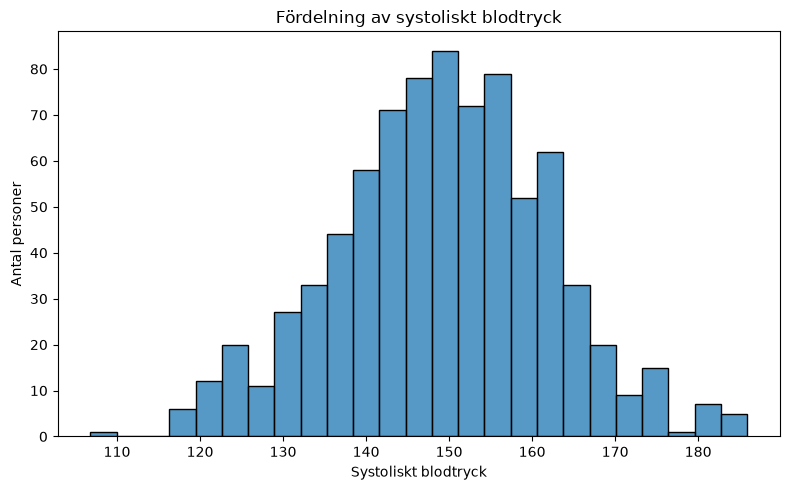

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="systolic_bp", bins=25)

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck")
plt.ylabel("Antal personer")

plt.tight_layout()
plt.show()

### Viktfördelning per kön

En boxplot används för att jämföra viktens median och spridning
mellan könsgrupperna. Lådan sträcker sig från första till tredje
kvartilen och innehåller därmed de mittersta 50 procenten av
värdena. Linjen i lådan visar medianen.

Med standardinställningen sträcker sig morrhåren till de yttersta
observationerna inom 1,5 gånger kvartilavståndet från lådans
kanter. Värden utanför dessa gränser visas som separata punkter.
De är potentiella extremvärden, men inte automatiskt felaktiga.

Dokumentation:
- [seaborn.boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)

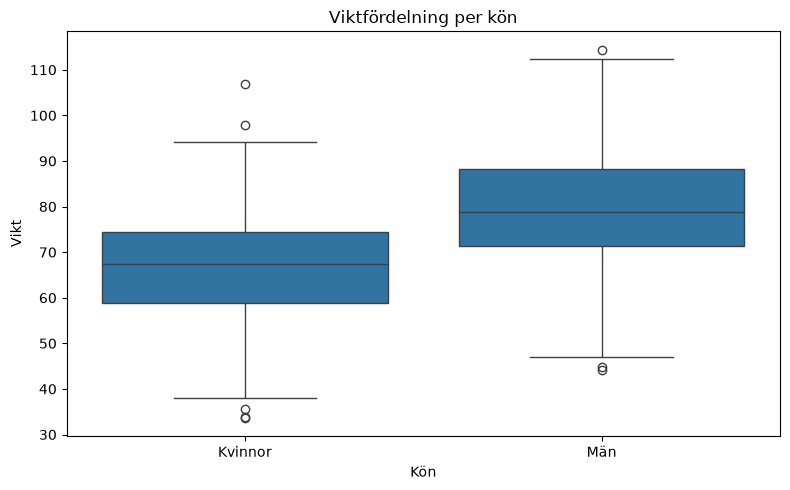

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="sex", y="weight", order=["F", "M"])

plt.title("Viktfördelning per kön")
plt.xlabel("Kön")
plt.ylabel("Vikt")
plt.xticks([0, 1], ["Kvinnor", "Män"])

plt.tight_layout()
plt.show()

#### Män har högre medianvikt än kvinnor i datasetet, men fördelningarna överlappar. Spridningen bland de mittersta 50 procenten är något större för män. Båda grupperna har potentiella extremvärden.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Andel rökare och icke-rökare

Ett stapeldiagram används för att jämföra andelen personer i
de två rökkategorierna. Med `value_counts(normalize=True)`
beräknas relativa frekvenser, som multipliceras med 100 för
att uttryckas i procent. `reindex()` bestämmer kategoriernas
ordning och `plot(kind="bar")` skapar stapeldiagrammet.

Y-axeln visas från 0 till 100 procent för att tydliggöra
gruppernas andelar av datasetet.

Dokumentation:
- [Series.value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
- [Series.reindex](https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html)
- [Series.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.bar.html)

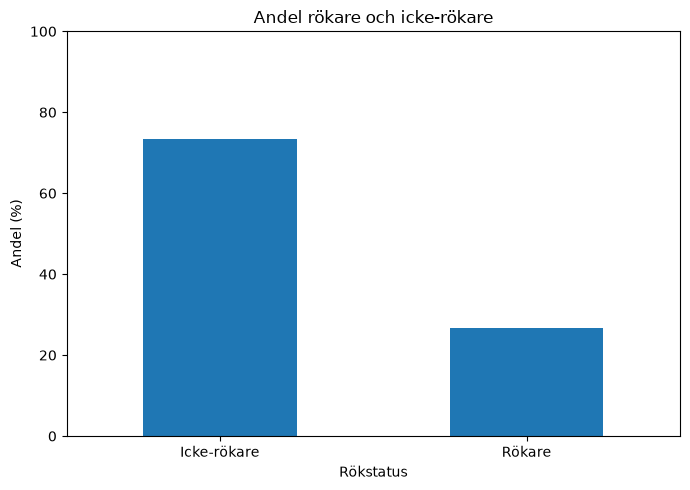

smoker
No     73.4
Yes    26.6
Name: proportion, dtype: float64


In [8]:
smoker_percent = (
    df["smoker"]
    .value_counts(normalize=True)
    .reindex(["No", "Yes"]) * 100
)

plt.figure(figsize=(7, 5))

smoker_percent.plot(kind="bar", rot=0)

plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökstatus")
plt.ylabel("Andel (%)")
plt.xticks([0, 1], ["Icke-rökare", "Rökare"])
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

print(smoker_percent.round(1))

#### I datasetet är ungefär 27 % av personerna rökare och 73 % icke-rökare.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Kontroll av sjukdomsvariabeln

Antalet observationer per värde i `disease` kontrolleras med
`value_counts(dropna=False)`. Inställningen gör att även eventuella
saknade värden visas. I analysen tolkas 1 som sjukdom och 0 som
ingen sjukdom.

Dokumentation:
- [Series.value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)

In [9]:
df["disease"].value_counts(dropna=False)

disease
0    753
1     47
Name: count, dtype: int64

### Simulering av sjukdomsförekomst

Eftersom sjukdom är kodad som 0 och 1 motsvarar variabelns
medelvärde andelen personer med sjukdom.

Den observerade andelen används som sannolikhet i en simulering
av 1 000 oberoende personer. `Generator.binomial(n=1, ...)`
genererar ett binärt utfall per person, vilket motsvarar ett
Bernoulli-försök. Modellen antar samma sjukdomssannolikhet för
alla simulerade personer.

Ett fast seed används för reproducerbarhet i samma programmiljö.
Skillnaden mellan observerad och simulerad andel illustrerar
slumpvariation; simuleringen verifierar inte populationens
verkliga sjukdomsförekomst.

Dokumentation:
- [Series.mean](https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html)
- [NumPy Random Generator och seed](https://numpy.org/doc/stable/reference/random/generator.html)
- [Generator.binomial](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.binomial.html)

In [10]:
# Observerad andel med sjukdom
disease_probability = df["disease"].mean()

# Fast seed gör simuleringen reproducerbar
rng = np.random.default_rng(seed=42)

# Varje person får värdet 0 eller 1
simulated_disease = rng.binomial(
    n=1,
    p=disease_probability,
    size=1000
)

# Jämför observerad och simulerad andel
simulated_proportion = simulated_disease.mean()

print(f"Observerad andel: {disease_probability:.2%}")
print(f"Simulerad andel:  {simulated_proportion:.2%}")

Observerad andel: 5.88%
Simulerad andel:  5.40%


#### I datasetet har 47 av 800 personer sjukdomen, vilket motsvarar cirka 5,88 %. Vid simulering av 1 000 personer med samma sjukdomssannolikhet fick 5,40 % sjukdomen. Skillnaden beror på slumpvariation. Ett fast seed gör simuleringen reproducerbar.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Konfidensintervall med normalapproximation

Ett approximativt 95-procentigt konfidensintervall för
populationens medelvärde beräknas som medelvärdet ± 1,96
gånger standardfelet.

Standardfelet skattas som stickprovets standardavvikelse
dividerad med kvadratroten av antalet observationer.
`std(ddof=1)` beräknar stickprovets standardavvikelse.

Normalapproximationen motiveras av det stora stickprovet
(n = 800). Eftersom populationsstandardavvikelsen är okänd
är ett t-intervall ett alternativ, men vid denna
stickprovsstorlek ligger t-kvantilen mycket nära 1,96.

Beräkningen förutsätter oberoende observationer. Möjligheten
att generalisera resultatet beror även på hur urvalet gjorts.

Källor:
- [NIST: Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)
- [Series.std](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html)
- [numpy.sqrt](https://numpy.org/doc/stable/reference/generated/numpy.sqrt.html)

In [11]:
bp = df["systolic_bp"].dropna()

n = len(bp)
mean_bp = bp.mean()
std_bp = bp.std(ddof=1)
standard_error = std_bp / np.sqrt(n)

ci_lower = mean_bp - 1.96 * standard_error
ci_upper = mean_bp + 1.96 * standard_error

print(f"Medelvärde: {mean_bp:.2f}")
print(f"Standardfel: {standard_error:.2f}")
print(f"95 % konfidensintervall: ({ci_lower:.2f}, {ci_upper:.2f})")

Medelvärde: 149.18
Standardfel: 0.45
95 % konfidensintervall: (148.29, 150.07)


#### Medelvärdet för systoliskt blodtryck är 149,18. Med normalapproximation beräknas ett 95-procentigt konfidensintervall till [148,29; 150,07]. Intervallet beskriver osäkerheten i skattningen av populationens medelvärde, under antagandet om oberoende och representativa observationer. Vid upprepade slumpmässiga stickprov skulle ungefär 95 % av intervallen som beräknas med denna metod innehålla det sanna populationsmedelvärdet.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Konfidensintervall med percentil-bootstrap

Ett 95-procentigt konfidensintervall beräknas även med
percentil-bootstrap för jämförelse med normalapproximationen.

Med `choice(replace=True)` dras 10 000 stickprov med återläggning
från de observerade blodtrycksvärdena. Varje stickprov har
samma storlek som originalet, och dess medelvärde beräknas.
Den 2,5:e och 97,5:e percentilen av dessa medelvärden används
som intervallets gränser.

Metoden kräver inte att de ursprungliga observationerna antas
vara normalfördelade. Den förutsätter här oberoende observationer
och undanröjer inte eventuell snedvridning i urvalet.
Ett fast seed används för reproducerbarhet.

SciPys dokumentation beskriver percentilmetoden, men i denna
analys implementeras den med NumPy.

Källor:
- [SciPy: percentil-bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)
- [Generator.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)
- [numpy.percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html)

In [12]:
rng_bootstrap = np.random.default_rng(seed=43)

bootstrap_means = np.array([
    rng_bootstrap.choice(bp, size=len(bp), replace=True).mean()
    for _ in range(10000)
])

bootstrap_lower, bootstrap_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print(
    f"95 % bootstrap-intervall: "
    f"({bootstrap_lower:.2f}, {bootstrap_upper:.2f})"
)

95 % bootstrap-intervall: (148.28, 150.06)


#### Normalapproximation och percentil-bootstrap ger nästan identiska 95-procentiga konfidensintervall för medelvärdet av systoliskt blodtryck. Slutsatsen påverkas därför mycket lite av metodvalet i detta dataset. Båda metoderna förutsätter här oberoende observationer; bootstrap undanröjer inte eventuell snedvridning i urvalet.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Beskrivande jämförelse mellan rökgrupper

Observationerna grupperas efter rökstatus med `groupby()`.
För systoliskt blodtryck beräknas antal observationer,
medelvärde och standardavvikelse inom respektive grupp
med `agg()`.

Sammanfattningen används för att undersöka gruppstorlekar,
skillnaden i medelvärde och spridningen inför hypotesprövningen.
Resultaten visas med två decimaler med `round(2)`.

Dokumentation:
- [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)
- [DataFrameGroupBy.agg](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html)

In [13]:
df.groupby("smoker")["systolic_bp"].agg(
    ["count", "mean", "std"]
).round(2)

,count,mean,std
smoker,,,
No,587,149.05,12.63
Yes,213,149.52,13.27


### Hypotesprövning med ensidigt Welch-t-test

Ett ensidigt Welch-t-test används för att undersöka om
rökare har högre medelvärde för systoliskt blodtryck än
icke-rökare.

- H₀: Rökarnas populationsmedelvärde är lika högt eller lägre.
- H₁: Rökarnas populationsmedelvärde är högre.
- Signifikansnivå: α = 0,05.

Welch-testet väljs eftersom det tillåter olika varians
och olika gruppstorlekar. Testet förutsätter oberoende
observationer. De relativt stora grupperna ger stöd för
approximationen för gruppmedelvärdenas fördelningar.

I `ttest_ind()` väljer `equal_var=False` Welch-testet.
`alternative="greater"` testar om den första gruppens
populationsmedelvärde är högre än den andras. Därför anges
rökarna först. Testets riktning följer uppgiftens hypotes.

Jämförelsen justeras inte för andra variabler, exempelvis
ålder, och kan inte i sig visa ett orsakssamband.

Dokumentation:
- [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

In [14]:
from scipy.stats import ttest_ind

smokers_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers_bp = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

test_result = ttest_ind(
    smokers_bp,
    non_smokers_bp,
    equal_var=False,
    alternative="greater"
)

mean_difference = smokers_bp.mean() - non_smokers_bp.mean()

print(f"Skillnad i medelblodtryck: {mean_difference:.2f}")
print(f"t-värde: {test_result.statistic:.3f}")
print(f"p-värde: {test_result.pvalue:.4f}")

Skillnad i medelblodtryck: 0.47
t-värde: 0.450
p-värde: 0.3264


#### Ett ensidigt Welch-t-test användes för att undersöka om rökare har högre medelvärde för systoliskt blodtryck än icke-rökare. Testet tillåter olika varians och olika gruppstorlekar och förutsätter oberoende observationer. Rökarnas medelvärde var 149,52 och icke-rökarnas 149,05, en skillnad på cirka 0,47. Resultatet var inte statistiskt signifikant (t = 0,450; p = 0,3264). Vid signifikansnivån 0,05 kan nollhypotesen därför inte förkastas. Resultatet visar inte att gruppernas medelvärden är lika.

** värdera att radera denna text, alternativt kraftigt redigera den **

In [15]:
rng_power = np.random.default_rng(seed=44)

n_simulations = 5000
alpha = 0.05
assumed_difference = 5

n_smokers = len(smokers_bp)
n_non_smokers = len(non_smokers_bp)

baseline_mean = non_smokers_bp.mean()
sd_smokers = smokers_bp.std(ddof=1)
sd_non_smokers = non_smokers_bp.std(ddof=1)

significant_results = 0

for _ in range(n_simulations):
    simulated_smokers = rng_power.normal(
        loc=baseline_mean + assumed_difference,
        scale=sd_smokers,
        size=n_smokers
    )

    simulated_non_smokers = rng_power.normal(
        loc=baseline_mean,
        scale=sd_non_smokers,
        size=n_non_smokers
    )

    result = ttest_ind(
        simulated_smokers,
        simulated_non_smokers,
        equal_var=False,
        alternative="greater"
    )

    if result.pvalue < alpha:
        significant_results += 1

estimated_power = significant_results / n_simulations

print(f"Antagen verklig skillnad: {assumed_difference}")
print(f"Antal simuleringar: {n_simulations}")
print(f"Uppskattad power: {estimated_power:.1%}")

Antagen verklig skillnad: 5
Antal simuleringar: 5000
Uppskattad power: 99.9%


#### Vid en antagen verklig skillnad på 5 enheter uppskattades testets power till 99,9 % genom 5 000 simuleringar. Simuleringen använde datasetets gruppstorlekar och standardavvikelser samt antog normalfördelade, oberoende observationer. Testet har därmed mycket hög sannolikhet att upptäcka en skillnad av denna storlek under dessa antaganden. Resultatet gäller det valda scenariot och innebär inte att mindre skillnader upptäcks lika ofta.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Power genom simulering

Testets power undersöks genom att simulera oberoende,
normalfördelade blodtrycksvärden för rökare och icke-rökare.
Gruppstorlekar och standardavvikelser hämtas från datasetet.
Icke-rökarnas observerade medelvärde används som baslinje,
medan rökarnas medelvärde förskjuts med en antagen skillnad.

För varje scenario skapas 5 000 dataset. Samma ensidiga
Welch-test genomförs på varje dataset med signifikansnivån
0,05. Andelen signifikanta test uppskattar power när den
antagna skillnaden är positiv. Vid skillnaden noll uppskattas
i stället testets falska positiva frekvens.

Resultaten gäller under simuleringens antaganden. De anger
inte sannolikheten att slutsatsen från det ursprungliga
testet är korrekt. Uppskattningarna innehåller också
Monte Carlo-osäkerhet eftersom antalet simuleringar är begränsat.

Simuleringen implementeras med en egen loop, NumPys
normalgenerator och SciPys Welch-test. Dokumentationen
för `scipy.stats.power` används som metodstöd; den funktionen
anropas inte i vår kod.

Källor:
- [SciPy: simulering av power](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html)
- [Generator.normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html)
- [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

In [16]:
def estimate_power(assumed_difference, seed=44):
    rng_power = np.random.default_rng(seed=44)

    n_simulations = 5000
    alpha = 0.05

    n_smokers = len(smokers_bp)
    n_non_smokers = len(non_smokers_bp)

    baseline_mean = non_smokers_bp.mean()
    sd_smokers = smokers_bp.std(ddof=1)
    sd_non_smokers = non_smokers_bp.std(ddof=1)

    significant_results = 0

    for _ in range(n_simulations):
        simulated_smokers = rng_power.normal(
            loc=baseline_mean + assumed_difference,
            scale=sd_smokers,
            size=n_smokers
        )

        simulated_non_smokers = rng_power.normal(
            loc=baseline_mean,
            scale=sd_non_smokers,
            size=n_non_smokers
        )

        result = ttest_ind(
            simulated_smokers,
            simulated_non_smokers,
            equal_var=False,
            alternative="greater"
        )

        if result.pvalue < alpha:
            significant_results += 1

    estimated_power = significant_results / n_simulations

    return estimated_power

### Jämförelse mellan antagna skillnader

Funktionen `estimate_power()` körs för antagna skillnader på
0, 0,5, 1, 2, 3 och 5. Scenarierna illustrerar hur testets
förmåga förändras med skillnadens storlek. Värdena är valda
för jämförelsen och representerar inte fastställda kliniska
gränser.

Resultaten samlas i en pandas DataFrame. Andelen signifikanta
test redovisas både som andel och procent. Vid skillnaden
noll avser resultatet falska positiva test; för positiva
skillnader avser det power.

Samma seed används för varje scenario, vilket innebär att
samma underliggande slumptal återanvänds. Det underlättar
jämförelsen, men resultaten mellan scenarierna är inte
oberoende.

Källor:
- [SciPy: simulering av power](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html)
- [pandas.DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html)
- [NumPy Random Generator och seed](https://numpy.org/doc/stable/reference/random/generator.html)

In [17]:
power_results = pd.DataFrame({
    "assumed_difference": [0, 0.5, 1, 2, 3, 5]
})

power_results["rejection_rate"] = [
    estimate_power(difference)
    for difference in power_results["assumed_difference"]
]

power_results["rejection_percent"] = (
    power_results["rejection_rate"] * 100
)

power_results.round(2)

,assumed_difference,rejection_rate,rejection_percent
0,0.0,0.05,5.28
1,0.5,0.12,11.76
2,1.0,0.25,24.86
3,2.0,0.60,60.26
4,3.0,0.89,89.36
5,5.0,1.00,99.92


#### Simuleringen visar att testets power ökar med den antagna verkliga skillnaden mellan gruppernas medelvärden. Vid skillnader på 0,5 respektive 1 var power cirka 12 % respektive 25 %, medan en skillnad på 3 upptäcktes i cirka 89 % av simuleringarna. När ingen skillnad fanns blev 5,28 % av testen signifikanta, nära den valda signifikansnivån 5 %. Resultaten gäller under antagandet om normalfördelade, oberoende observationer och de gruppstorlekar och standardavvikelser som användes.

### Visualisering av power-simuleringen

Andelen signifikanta test ritas mot den antagna verkliga
skillnaden i medelblodtryck. Punkterna visar simuleringsresultaten
för respektive scenario. Linjerna mellan dem är en visuell
sammanbindning och representerar inga ytterligare simuleringar.

Vid skillnaden noll visar grafen den uppskattade falska positiva
frekvensen. Vid positiva skillnader visar den uppskattad power.
En horisontell linje vid 80 procent används som visuell
referensnivå, inte som ett krav i uppgiften.

Dokumentation:
- [matplotlib.pyplot.plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)
- [matplotlib.pyplot.axhline](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)

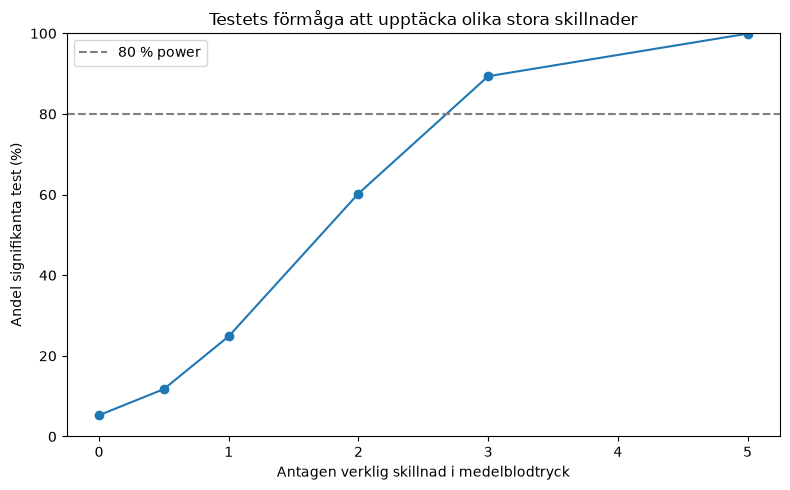

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    power_results["assumed_difference"],
    power_results["rejection_percent"],
    marker="o"
)

plt.axhline(
    80, color="gray", linestyle="--", label="80 % power"
)

plt.title("Testets förmåga att upptäcka olika stora skillnader")
plt.xlabel("Antagen verklig skillnad i medelblodtryck")
plt.ylabel("Andel signifikanta test (%)")
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()

In [19]:
import sys
from importlib.metadata import version

print(f"Python: {sys.version.split()[0]}")

for package in ["numpy", "pandas", "seaborn", "matplotlib", "scipy"]:
    print(f"{package}=={version(package)}")

Python: 3.14.7
numpy==2.5.4
pandas==3.0.6
seaborn==0.13.2
matplotlib==3.11.2
scipy==1.18.1
